# Fourier Features: Teaching an MLP High-Frequency Detail (pure NumPy)

In this assignment you will create a coordinate-based multilayer perceptron in numpy from scratch. For each input image coordinate $(x,y)$, the model predicts the associated color $(r,g,b)$.

![Network diagram](../assets/network_diagram.png)

You will then compare the following input feature mappings $\gamma (\mathbf{v})$.

- No mapping: $\gamma(\mathbf{v})= \mathbf{v}$. 

- Basic mapping: $\gamma(\mathbf{v})=\left[ \cos(2 \pi \mathbf{v}),\sin(2 \pi \mathbf{v}) \right]^\mathrm{T}$. (Note that the comma indicates a concatenation along the feature dimension.)

- Gaussian Fourier feature mapping: $\gamma(\mathbf{v})= \left[ \cos(2 \pi \mathbf B \mathbf{v}), \sin(2 \pi \mathbf B \mathbf{v}) \right]^\mathrm{T}$, 
where each entry in $\mathbf B \in \mathbb R^{m \times d}$ is sampled from $\mathcal N(0,\sigma^2)$. You should show results for $\sigma$ = 1 and 10. The starter code uses $m = s / 2$, where $s$ is the image side length in pixels; you can leave this alone, although you can also experiment with different values of $m$ and report your observations for extra credit.

Also, note that:
- You will implement the mappings in the helper functions `get_B_dict` and `input_mapping`. 
- The basic mapping can be considered a case where $\mathbf B \in \mathbb R^{2 \times 2}$ is the identity matrix. 
- For this assignment, $d$ is 2 because the input coordinates are in two dimensions.
- For SGD with the default hyperparameters, the expected reconstructions will be blurry to some extent.

Source: https://bmild.github.io/fourfeat/ 
This assignment is inspired by and built off of the authors' demo. 

## Setup

In [49]:
# Make the repository root the working directory so `src/` resolves
import os, sys
if os.path.basename(os.getcwd()) == "notebooks":
    os.chdir("..")
sys.path.insert(0, "src")

### Imports

In [51]:
import warnings
warnings.filterwarnings('ignore')
import matplotlib
matplotlib.use('Agg')
import matplotlib.pyplot as plt
from tqdm.notebook import tqdm
import os, imageio
import cv2
import numpy as np

from models.neural_net import NeuralNetwork

%load_ext autoreload
%autoreload 2

%matplotlib inline
plt.rcParams['figure.figsize'] = (10.0, 8.0)

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


## Helper Functions

### Image Data and Feature Mappings (Fill in TODOs)

In [52]:
# Data loader - already done for you
def get_image(size=512, image_url='https://bmild.github.io/fourfeat/img/lion_orig.png'):
  import os
  # Use local cache if available (avoids network errors)
  local_name = os.path.basename(image_url)
  if os.path.exists(local_name):
    img = imageio.imread(local_name)[..., :3] / 255.
  else:
    img = imageio.imread(image_url)[..., :3] / 255.

  # Take a square crop from the center
  h, w = img.shape[0], img.shape[1]
  r = min(h, w) // 2
  c = [h // 2, w // 2]
  img = img[c[0]-r:c[0]+r, c[1]-r:c[1]+r]

  if size != img.shape[0]:
    img = cv2.resize(img, (size, size))

  plt.imshow(img)
  plt.show()

  # Create input pixel coordinates in the unit square
  coords = np.linspace(0, 1, img.shape[0], endpoint=False)
  x_test = np.stack(np.meshgrid(coords, coords), -1)
  test_data = [x_test, img]
  train_data = [x_test[::2, ::2], img[::2, ::2]]

  return train_data, test_data

In [53]:
# Create the mappings dictionary of matrix B -  you will implement this
def get_B_dict(size):
  mapping_size = size // 2
  B_dict = {}
  B_dict['none'] = None

  # Basic: identity 2x2
  B_dict['basic'] = np.eye(2)

  # Fourier sigma=1
  B_dict['gauss_1.0'] = np.random.randn(mapping_size, 2) * 1.0

  # Fourier sigma=10
  B_dict['gauss_10.0'] = np.random.randn(mapping_size, 2) * 10.0

  return B_dict

In [54]:
# Given tensor x of input coordinates, map it using B - you will implement
def input_mapping(x, B):
  if B is None:
    return x
  else:
    x_proj = 2 * np.pi * x @ B.T
    return np.concatenate([np.cos(x_proj), np.sin(x_proj)], axis=-1)

### MSE Loss and PSNR Error (Fill in TODOs)

For the MSE loss, you should implement the following:

MSE = $0.5 \frac{1}{NC} \sum \limits_{i=1}^N \sum \limits_{j=1}^C (y_{ij} - p_{ij})^2$

where $y$ and $p$ are of shape $(N, C)$.

In [55]:
def mse(y, p):
  # TODO implement this
  # make sure it is consistent with your implementation in neural_net.py
  return 0.5 * np.mean((y - p) ** 2)

def psnr(y, p):
  return -10 * np.log10(2.*mse(y, p))

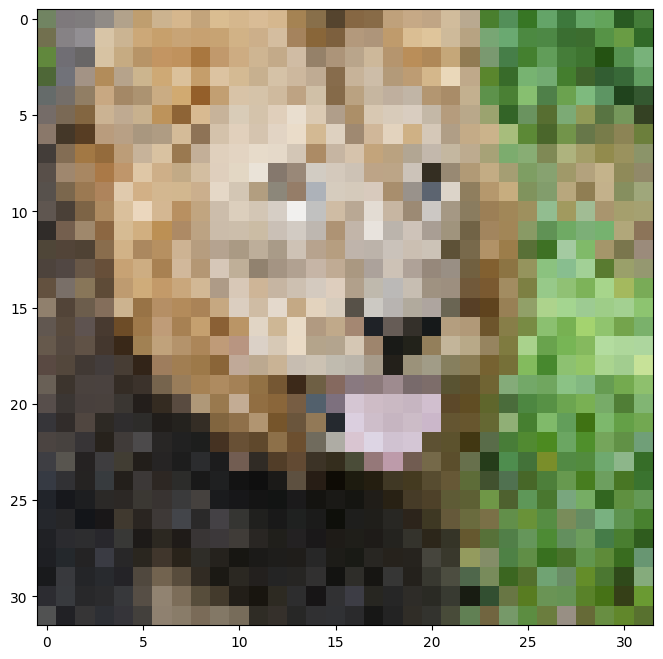

In [56]:
size = 32
train_data, test_data = get_image(size)

The default hyperparameters are as follows:
- number of layers: 4
- hidden layer size: 256
- number of epochs: 500
- learning rate: 0.1

You should implement SGD (i.e., one training example per weight update), and thus a mini-batch hyperparameter is not needed.

In [57]:
num_layers = 4
output_size = 3

hidden_size = 256
epochs = 500
learning_rate = 0.1

np.random.seed(42)
B_dict = get_B_dict(size)

print('B_dict items:')
for k,v in B_dict.items():
    print('\t',k,np.array(v).shape)

B_dict items:
	 none ()
	 basic (2, 2)
	 gauss_1.0 (16, 2)
	 gauss_10.0 (16, 2)


In [58]:
# Apply the input feature mapping to the train and test data - already done for you
def get_input_features(B_dict, mapping):
  # mapping is the key to the B_dict, which has the value of B
  # B is then used with the function `input_mapping` to map x  
  y_train = train_data[1].reshape(-1, output_size)
  y_test = test_data[1].reshape(-1, output_size)
  X_train = input_mapping(train_data[0].reshape(-1, 2), B_dict[mapping])
  X_test = input_mapping(test_data[0].reshape(-1, 2), B_dict[mapping])
  return X_train, y_train, X_test, y_test

### Plotting and video helper functions (you don't need to change anything here)

In [59]:
def plot_training_curves(train_loss, train_psnr, test_psnr):
  # plot the training loss
  plt.subplot(2, 1, 1)
  plt.plot(train_loss)
  plt.title('MSE history')
  plt.xlabel('Iteration')
  plt.ylabel('MSE Loss')

  # plot the training and testing psnr
  plt.subplot(2, 1, 2)
  plt.plot(train_psnr, label='train')
  plt.plot(test_psnr, label='test')
  plt.title('PSNR history')
  plt.xlabel('Iteration')
  plt.ylabel('PSNR')
  plt.legend()

  plt.tight_layout()
  plt.show()

def plot_reconstruction(p, y):
  p_im = p.reshape(size,size,3)
  y_im = y.reshape(size,size,3)

  plt.figure(figsize=(12,6))

  # plot the reconstruction of the image
  plt.subplot(1,2,1), plt.imshow(p_im), plt.title("reconstruction")

  # plot the ground truth image
  plt.subplot(1,2,2), plt.imshow(y_im), plt.title("ground truth")

  print("Final Test MSE", mse(y, p))
  print("Final Test psnr",psnr(y, p))

def plot_reconstruction_progress(predicted_images, y, N=8):
  total = len(predicted_images)
  step = total // N
  plt.figure(figsize=(24, 4))

  # plot the progress of reconstructions
  chosen = list(range(0,total, step))[:N]

  for i, j in enumerate(chosen):
      plt.subplot(1, N+1, i+1)
      plt.imshow(predicted_images[j].reshape(size,size,3))
      plt.axis("off")
      plt.title(f"iter {j}")

  # plot ground truth image
  plt.subplot(1, N+1, N+1)
  plt.imshow(y.reshape(size,size,3))
  plt.title('GT')
  plt.axis("off")
  plt.show()

def plot_feature_mapping_comparison(outputs, gt):
  # plot reconstruction images for each mapping
  plt.figure(figsize=(24, 4))
  N = len(outputs)
  for i, k in enumerate(outputs):
      plt.subplot(1, N+1, i+1)
      plt.imshow(outputs[k]['pred_imgs'][-1].reshape(size, size, -1))
      plt.title(k)
  plt.subplot(1, N+1, N+1)
  plt.imshow(gt)
  plt.title('GT')
  plt.show()

  # plot train/test error curves for each mapping
  iters = len(outputs[k]['train_psnrs'])
  plt.figure(figsize=(16, 6))
  plt.subplot(121)
  for i, k in enumerate(outputs):
      plt.plot(range(iters), outputs[k]['train_psnrs'], label=k)
  plt.title('Train error')
  plt.ylabel('PSNR')
  plt.xlabel('Training iter')
  plt.legend()
  plt.subplot(122)
  for i, k in enumerate(outputs):
      plt.plot(range(iters), outputs[k]['test_psnrs'], label=k)
  plt.title('Test error')
  plt.ylabel('PSNR')
  plt.xlabel('Training iter')
  plt.legend()
  plt.show()

  for k in outputs:
    print(f"Final Test PSNR for {k}", outputs[k]['test_psnrs'][-1])

# Save out video
def create_and_visualize_video(outputs, size=size, epochs=epochs, filename='training_convergence.mp4'):
  all_preds = np.concatenate([outputs[n]['pred_imgs'].reshape(epochs,size,size,3)[::25] for n in outputs], axis=-2)
  data8 = (255*np.clip(all_preds, 0, 1)).astype(np.uint8)
  f = os.path.join(filename)
  imageio.mimwrite(f, data8, fps=20)

  # Display video inline
  from IPython.display import HTML
  from base64 import b64encode
  mp4 = open(f, 'rb').read()
  data_url = "data:video/mp4;base64," + b64encode(mp4).decode()

  N = len(outputs)
  if N == 1:
    return HTML(f'''
    <video width=256 controls autoplay loop>
          <source src="{data_url}" type="video/mp4">
    </video>
    ''')
  else:
    return HTML(f'''
    <video width=1000 controls autoplay loop>
          <source src="{data_url}" type="video/mp4">
    </video>
    <table width="1000" cellspacing="0" cellpadding="0">
      <tr>{''.join(N*[f'<td width="{1000//len(outputs)}"></td>'])}</tr>
      <tr>{''.join(N*['<td style="text-align:center">{}</td>'])}</tr>
    </table>
    '''.format(*list(outputs.keys())))

### Experiment Runner (Fill in TODOs)

In [60]:
def NN_experiment(X_train, y_train, X_test, y_test, input_size, num_layers,
                  hidden_size, output_size, epochs, learning_rate, opt='SGD'):
    
    # Initialize the network
    hidden_sizes = [hidden_size] * (num_layers - 1)
    net = NeuralNetwork(input_size, hidden_sizes, output_size, num_layers, opt)

    # Arrays to store metrics during training
    train_loss = np.zeros(epochs)
    train_psnr = np.zeros(epochs)
    test_psnr = np.zeros(epochs)
    predicted_images = np.zeros((epochs, y_test.shape[0], y_test.shape[1]))

    for epoch in tqdm(range(epochs)):
        
        # Shuffle pixels randomly at each epoch
        idx = np.random.permutation(len(X_train))
        X_train = X_train[idx]
        y_train = y_train[idx]

        # Training — iterate over each pixel one by one (pure SGD)
        epoch_loss = 0
        for x, y in zip(X_train, y_train):
            
            # Reshape pixel from (D,) to (1, D)
            x = x.reshape(1, -1)
            y = y.reshape(1, -1)
            
            # Forward pass: predict the color of this pixel
            net.forward(x)
            
            # Backward pass: compute gradients and return loss
            loss = net.backward(y)
            
            # Accumulate loss over all pixels in the epoch
            epoch_loss += loss
            
            # SGD: update weights using computed gradients
            net.update(lr=learning_rate)
        
        # Compute average loss for this epoch
        train_loss[epoch] = epoch_loss / len(X_train)

        # Compute train PSNR — forward pass over all training pixels at once
        p_train = net.forward(X_train)
        train_psnr[epoch] = psnr(y_train, p_train)

        # Compute test PSNR and save predicted image
        p_test = net.forward(X_test)
        test_psnr[epoch] = psnr(y_test, p_test)
        predicted_images[epoch] = p_test

    return net, train_psnr, test_psnr, train_loss, predicted_images

# Low Resolution Reconstruction

#### Low Resolution Reconstruction - SGD - None Mapping

Using the default hyperparameters, for the low resolution reconstuction with
no feature mapping you should expect something like this:

![Low resolution reconstruction - None Mapping Example](../assets/low_res_none_example.png)

For verifying your implementation, the average test PSNR should reach approximately 18.

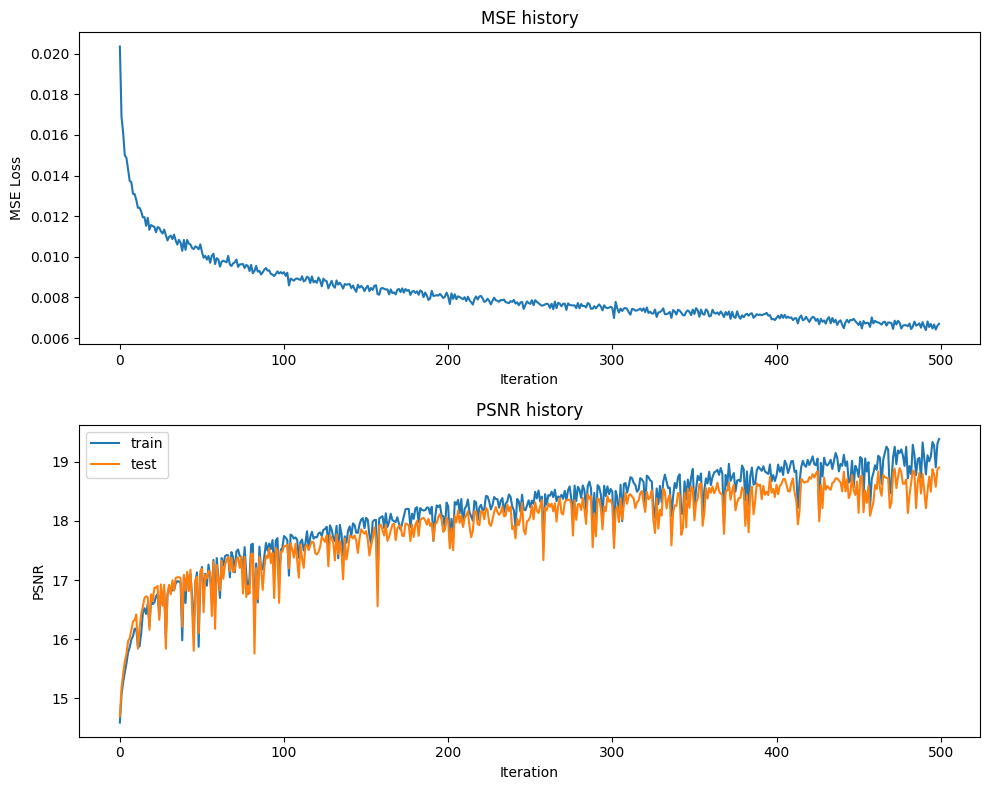

Final Test MSE 0.006432811501887767
Final Test psnr 18.905691787073575


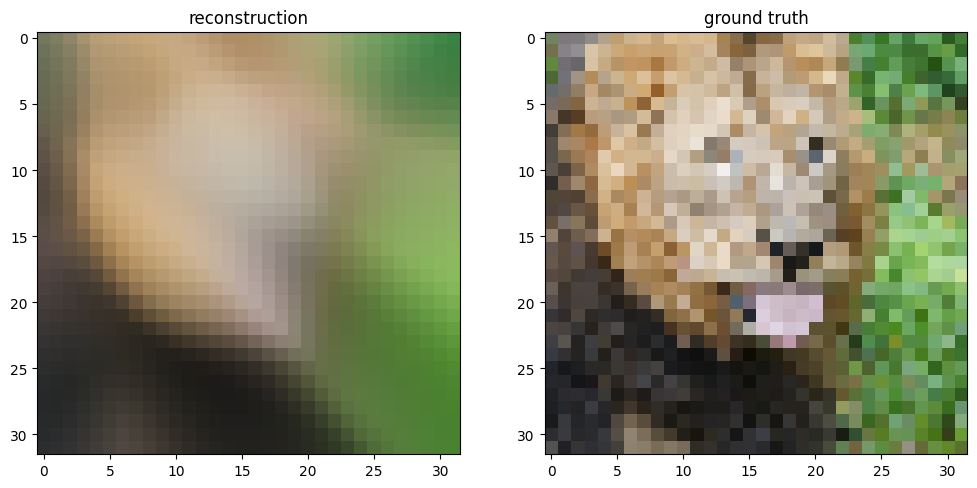

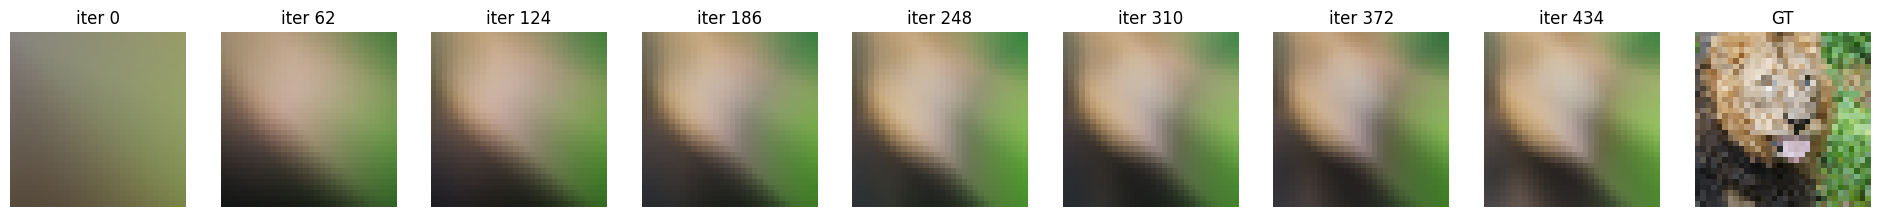

In [ ]:
X_train, y_train, X_test, y_test = get_input_features(B_dict, 'none')

# run NN_experiment on input features
net, train_psnr, test_psnr, train_loss, predicted_images = NN_experiment(
    X_train, y_train, X_test, y_test,
    input_size=X_train.shape[1],
    num_layers=num_layers,
    hidden_size=hidden_size,
    output_size=output_size,
    epochs=epochs,
    learning_rate=learning_rate,
    opt='SGD'
)

# plot results of experiment
plot_training_curves(train_loss, train_psnr, test_psnr)
plot_reconstruction(net.forward(X_test), y_test)
plot_reconstruction_progress(predicted_images, y_test)

#### Reconstruction Process Video (Optional)
(For Fun!) Visualize the progress of training in a video 

In [62]:
# requires installing this additional dependency
!pip install imageio-ffmpeg

In [63]:
# single video example
create_and_visualize_video({"gauss": {"pred_imgs": predicted_images}}, filename="training_high_res_gauss.mp4")

#### Low Resolution Reconstruction - SGD - Various Input Mapping Strategies

Using the default hyperparameters, for the low resolution reconstuction with
feature mappings (basic and Gaussian with $\sigma$ = 1 and 10) you should expect something like this:

![Low resolution reconstruction - Feature Mapping Examples](../assets/feature_mapping_example_low_res.png)

For verifying your implementation, your test PSNR should reach approximately the following values:
- None: 18
- Basic: 19
- Gaussian ($\sigma$=1): 19
- Gaussian ($\sigma$=10): 13

In [64]:
def train_wrapper(mapping, size, num_layers, hidden_size, output_size, epochs,  learning_rate, opt='SGD'):
    # TODO implement me
    # makes it easy to run all your mapping experiments in a for loop
    # this will be similar to what you did previously in the last two sections
     # Get input features for the given mapping
    X_train, y_train, X_test, y_test = get_input_features(B_dict, mapping)
    
    # Input size depends on the mapping used
    input_size = X_train.shape[1]
    
    # Run the experiment
    net, train_psnrs, test_psnrs, train_loss, predicted_images = NN_experiment(
        X_train, y_train, X_test, y_test,
        input_size, num_layers, hidden_size, output_size,
        epochs, learning_rate, opt
    )
    return {
        'net': net, 
        'train_psnrs': train_psnrs, 
        'test_psnrs': test_psnrs,
        'train_loss': train_loss,
        'pred_imgs': predicted_images
    }

In [65]:
outputs = {}
for k in tqdm(B_dict):
  print("training", k)
  outputs[k] = train_wrapper(k, size, num_layers, hidden_size, output_size, epochs, learning_rate, opt='SGD')

training none


training basic


training gauss_1.0


training gauss_10.0


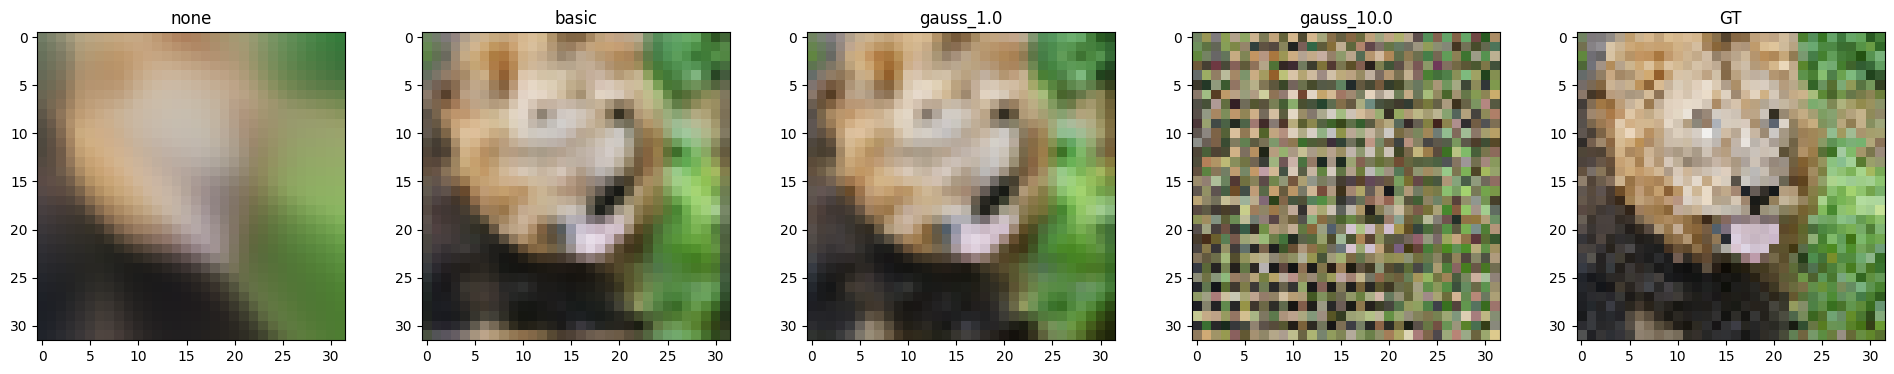

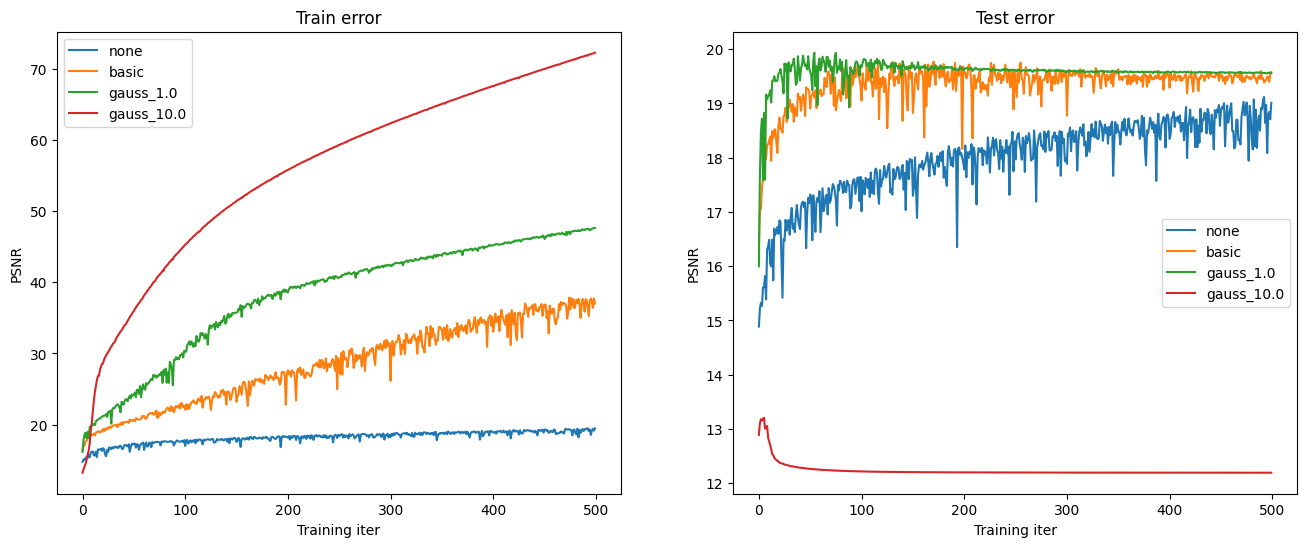

Final Test PSNR for none 19.01070837806415
Final Test PSNR for basic 19.574469626628346
Final Test PSNR for gauss_1.0 19.557115890847676
Final Test PSNR for gauss_10.0 12.192455368516612


In [66]:
# If you did everything correctly so far, this should output a nice figure you can use in your report.
# Note: With default settings, you should expect the Gaussian Fourier feature mapping to perform
# slightly better than the none and basic mappings, capturing more fine details in the reconstruction.
# However, the reconstruction will still be blurry to some extent and will not yield a great
# reconstruction with the default hyperparameters.
plot_feature_mapping_comparison(outputs, y_test.reshape(size,size,3))

#### Reconstruction Process Video (Optional)
(For Fun!) Visualize the progress of training in a video 

In [67]:
# multi video example
create_and_visualize_video(outputs, epochs=epochs, size=size)

,,,
none,basic,gauss_1.0,gauss_10.0


# High Resolution Reconstruction

#### High Resolution Reconstruction - SGD - Various Input Mapping Strategies

Repeat the previous experiment, but at the higher resolution. We have you first experiment with the lower resolution since it is faster to train and debug. Additionally, you will see how the mapping strategies perform better or worse at the two different input resolutions. 


Using the default hyperparameters, for the high resolution reconstuctions you should expect something like this:

![High resolution reconstructions](../assets/feature_mapping_example_high_res.png)

For verifying your implementation, your test PSNR should reach approximately the following values:
- None: 20
- Basic: 22
- Gaussian ($\sigma$=1): 23
- Gaussian ($\sigma$=10): 22

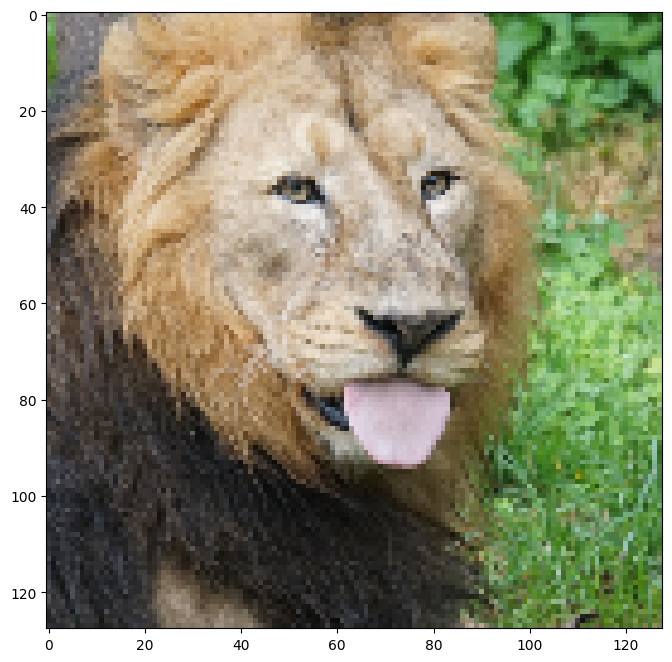

B_dict items:
	 none ()
	 basic (2, 2)
	 gauss_1.0 (64, 2)
	 gauss_10.0 (64, 2)


In [68]:
# load hi-res image
size = 128
train_data, test_data = get_image(size)

B_dict = get_B_dict(size)

print('B_dict items:')
for k,v in B_dict.items():
    print('\t',k,np.array(v).shape)

In [69]:
outputs = {}
for k in tqdm(B_dict):
  print("training", k)
  outputs[k] = train_wrapper(k,size, num_layers, hidden_size, output_size, epochs, learning_rate, opt='SGD')

training none


training basic


training gauss_1.0


training gauss_10.0


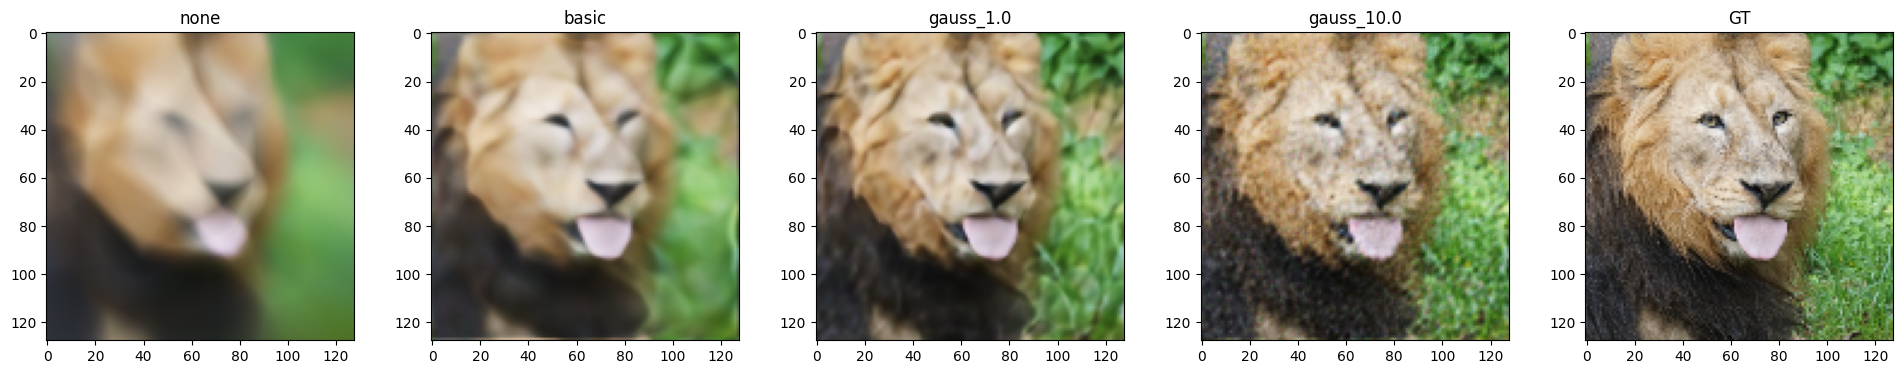

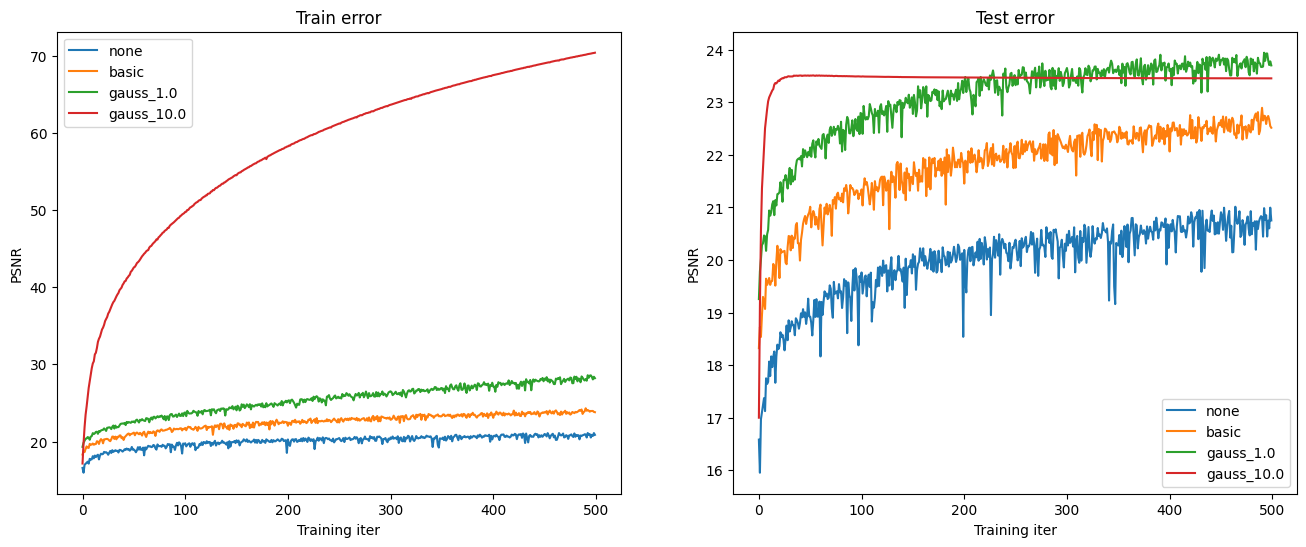

Final Test PSNR for none 20.7523789775723
Final Test PSNR for basic 22.515926617993472
Final Test PSNR for gauss_1.0 23.701841830465394
Final Test PSNR for gauss_10.0 23.455444669414995


In [70]:
_, _, _, y_test = get_input_features(B_dict, "none")  # for getting y_test

# If you did everything correctly so far, this should output a nice figure you can use in your report.
# Similar to the low resolution case, the Gaussian Fourier feature mapping should perform slightly
# better than the none and basic mappings, preserving more details. However, the reconstruction
# will still appear blurry to some extent and will not be a great reconstruction with default settings.
plot_feature_mapping_comparison(outputs, y_test.reshape(size,size,3))

#### Reconstruction Process Video (Optional)
(For Fun!) Visualize the progress of training in a video 

In [71]:
# multi video example
create_and_visualize_video(outputs, epochs=epochs, size=size)

,,,
none,basic,gauss_1.0,gauss_10.0


#### High Resolution Reconstruction - SGD - Image of Your Choice

When choosing an image, select one that you think will give you interesting results or a better insight into the performance of different feature mappings and record at least one interesting insight you gained.

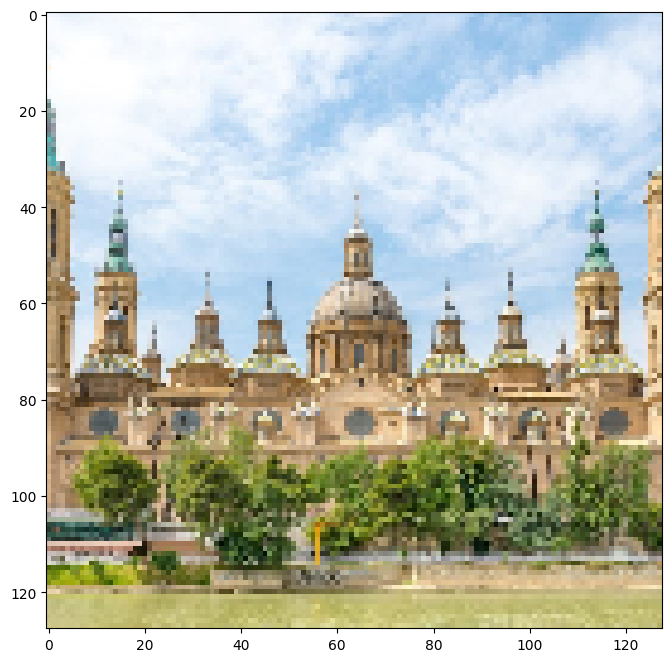

In [80]:
size = 128
# El Pilar de Zaragoza
train_data, test_data = get_image(size, image_url="https://espanaenlahistoria.org/wp-content/uploads/2021/08/basilica-nuestra-senora-pilar.jpg")

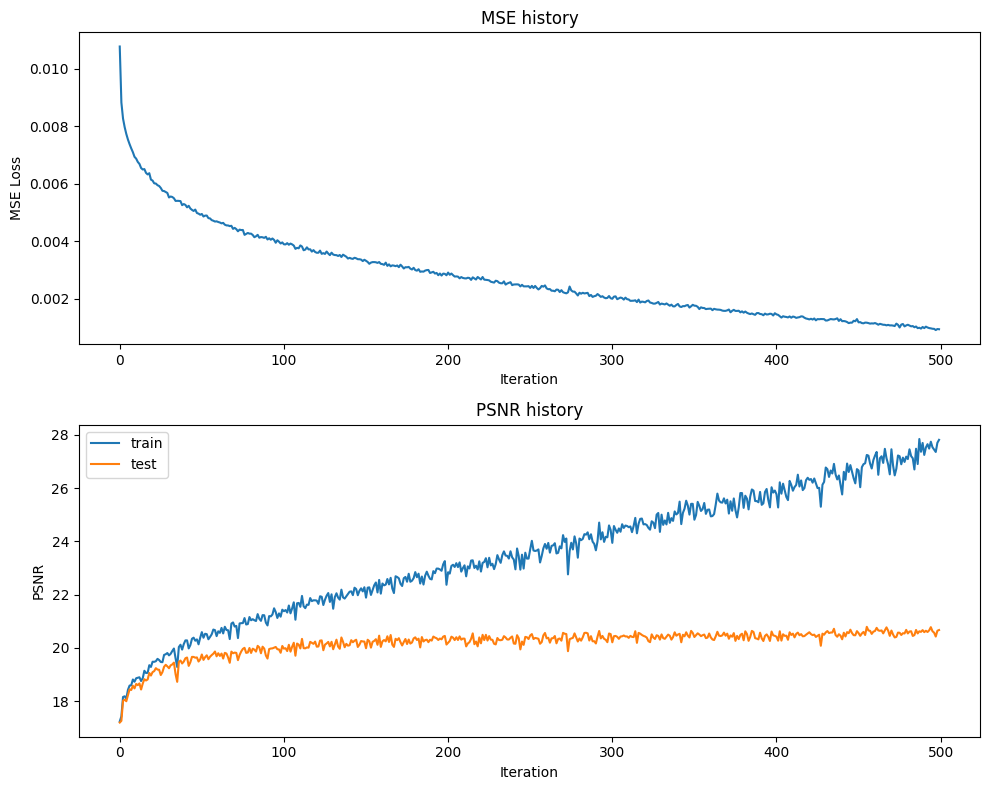

Final Test MSE 0.00428595435592781
Final Test psnr 20.669224627058593


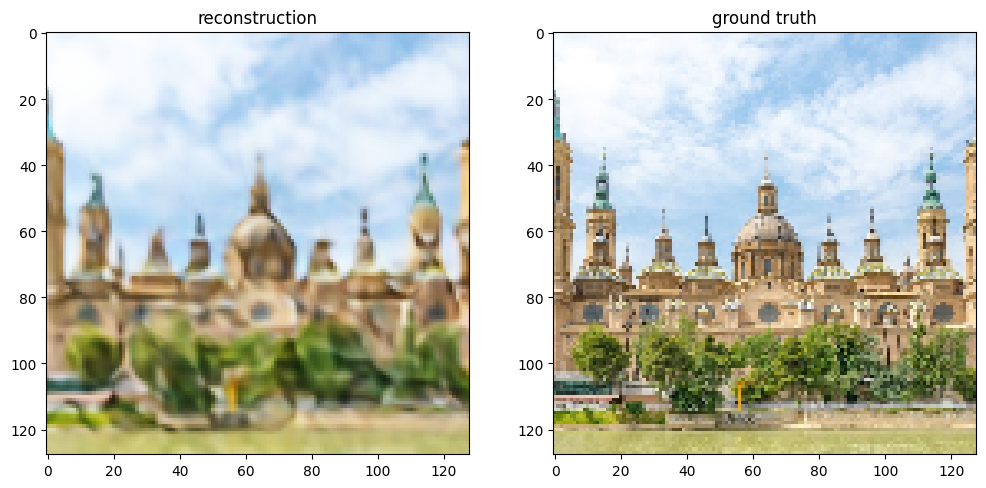

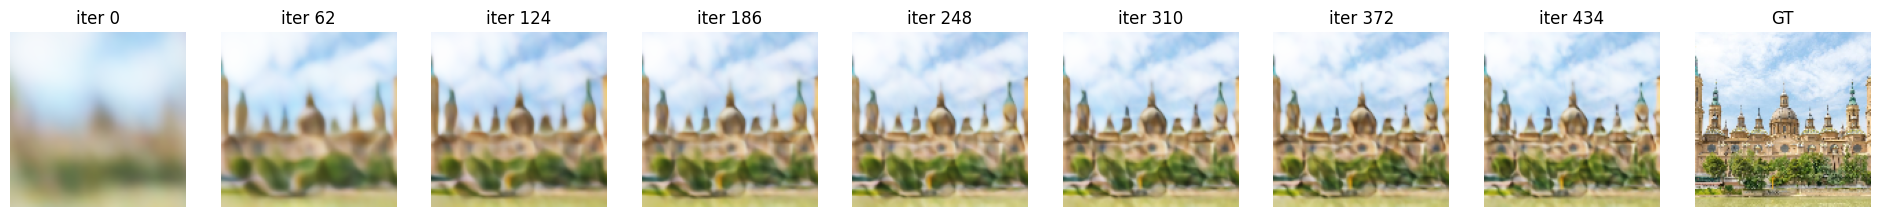

In [73]:
# Train with best mapping
B_dict = get_B_dict(size)
output = train_wrapper('gauss_1.0', size, num_layers, hidden_size, 
                        output_size, epochs, learning_rate, opt='SGD')

net = output['net']
train_psnr = output['train_psnrs']
test_psnr = output['test_psnrs']
train_loss = output['train_loss']
predicted_images = output['pred_imgs']

# Get X_test, y_test
X_train, y_train, X_test, y_test = get_input_features(B_dict, 'gauss_1.0')

# Plot results
plot_training_curves(train_loss, train_psnr, test_psnr)
plot_reconstruction(net.forward(X_test), y_test)
plot_reconstruction_progress(predicted_images, y_test)

# Adam Optimizer (implemented from scratch)

#### Low Resolution Reconstruction - Adam - None Mapping

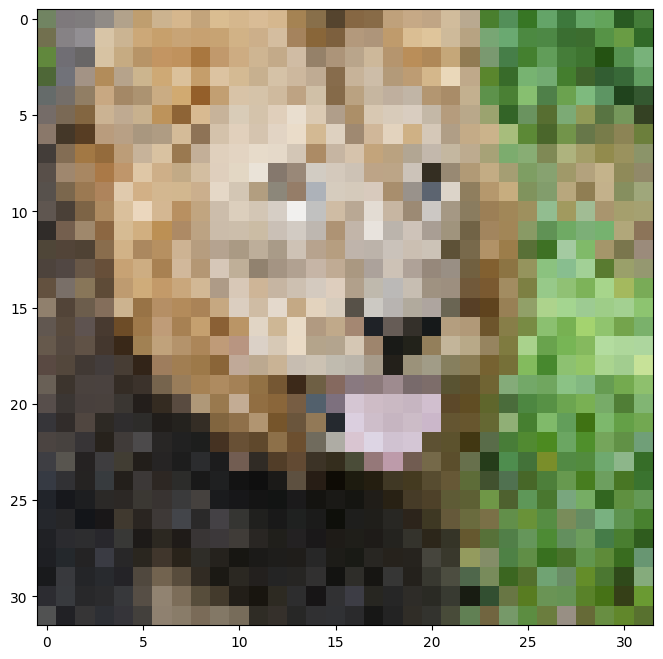

B_dict items:
	 none ()
	 basic (2, 2)
	 gauss_1.0 (16, 2)
	 gauss_10.0 (16, 2)


In [74]:
# load low-res image
size = 32
train_data, test_data = get_image(size)

B_dict = get_B_dict(size)

print('B_dict items:')
for k,v in B_dict.items():
    print('\t',k,np.array(v).shape)

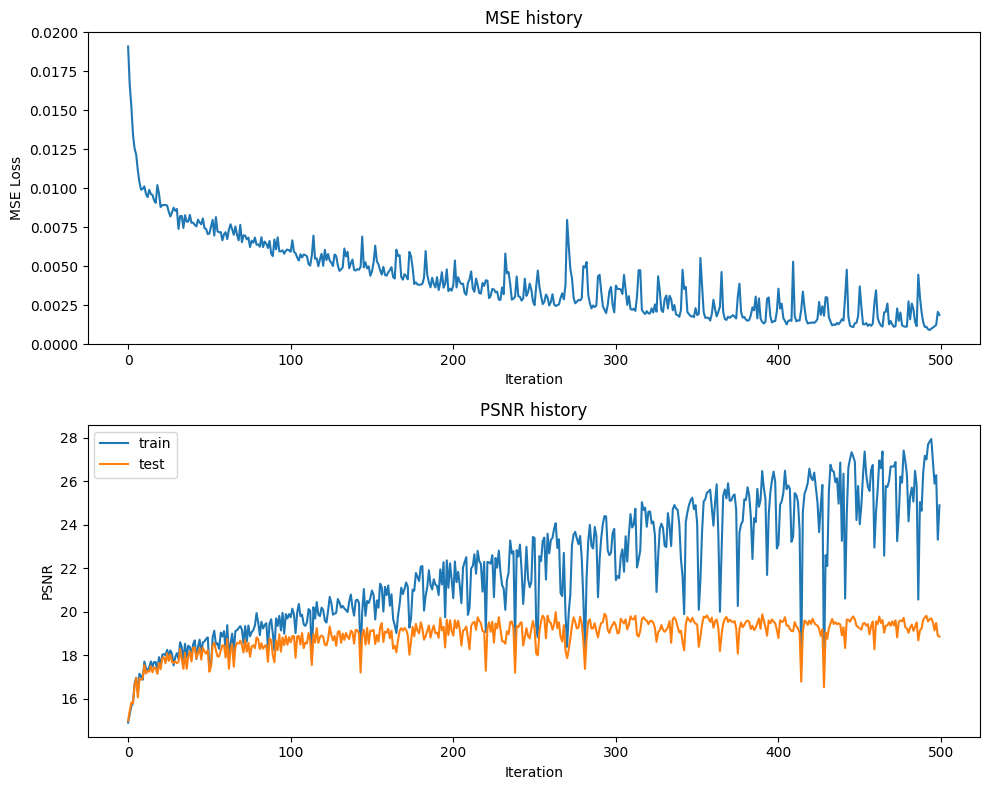

Final Test MSE 0.0064994379175756
Final Test psnr 18.860942045932372


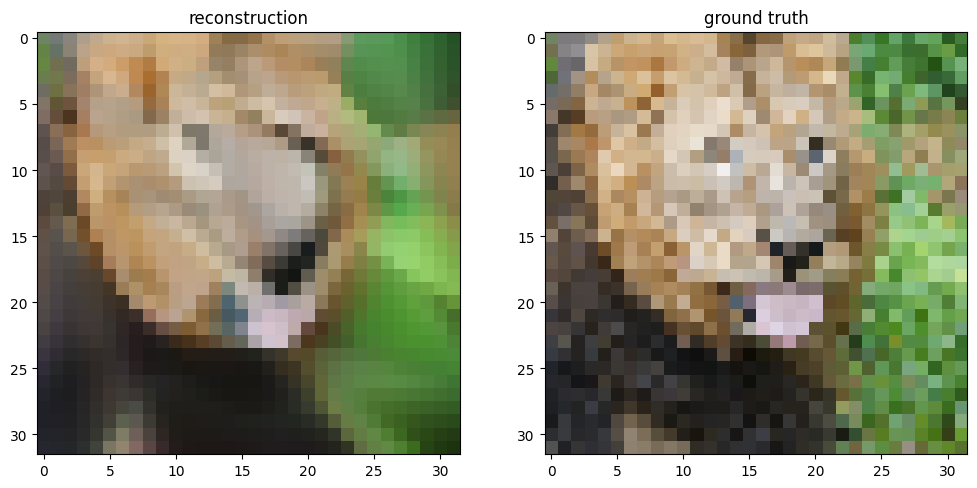

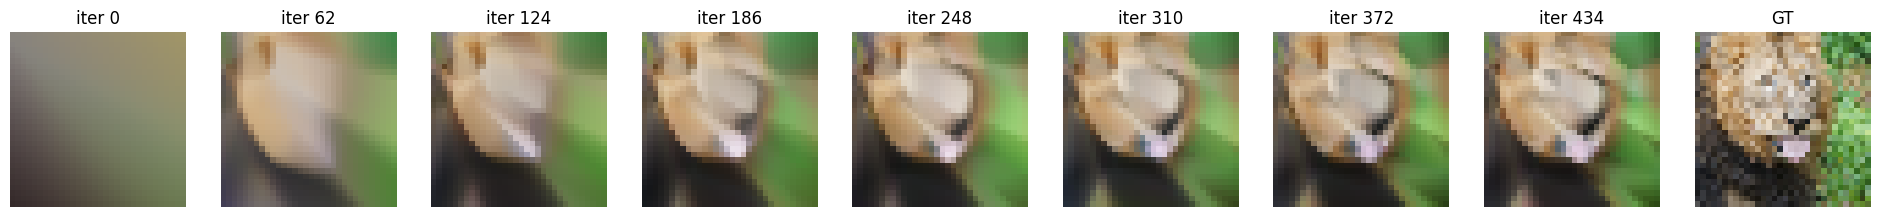

In [75]:
# Note: Adam typically needs a much smaller learning rate than SGD (e.g. 0.001)
adam_lr = 0.001

# TODO Use train_wrapper to retrieve newly trained model and data that will be plotted below
output = train_wrapper('none', size, num_layers, hidden_size,
                        output_size, epochs, adam_lr, opt='Adam')

net = output['net']
train_psnr = output['train_psnrs']
test_psnr = output['test_psnrs']
train_loss = output['train_loss']
predicted_images = output['pred_imgs']

# TODO Use get_input_features to retrieve X_test, y_test
X_train, y_train, X_test, y_test = get_input_features(B_dict, 'none')

# plot results of experiment
plot_training_curves(train_loss, train_psnr, test_psnr)
plot_reconstruction(net.forward(X_test), y_test)
plot_reconstruction_progress(predicted_images, y_test)

#### Low Resolution Reconstruction - Adam - Various Input Mapping Strategies

In [76]:
# start training
outputs = {}
for k in tqdm(B_dict):
  print("training", k)
  outputs[k] = train_wrapper(k, size, num_layers, hidden_size, output_size, epochs, adam_lr, opt='Adam')

training none


training basic


training gauss_1.0


training gauss_10.0


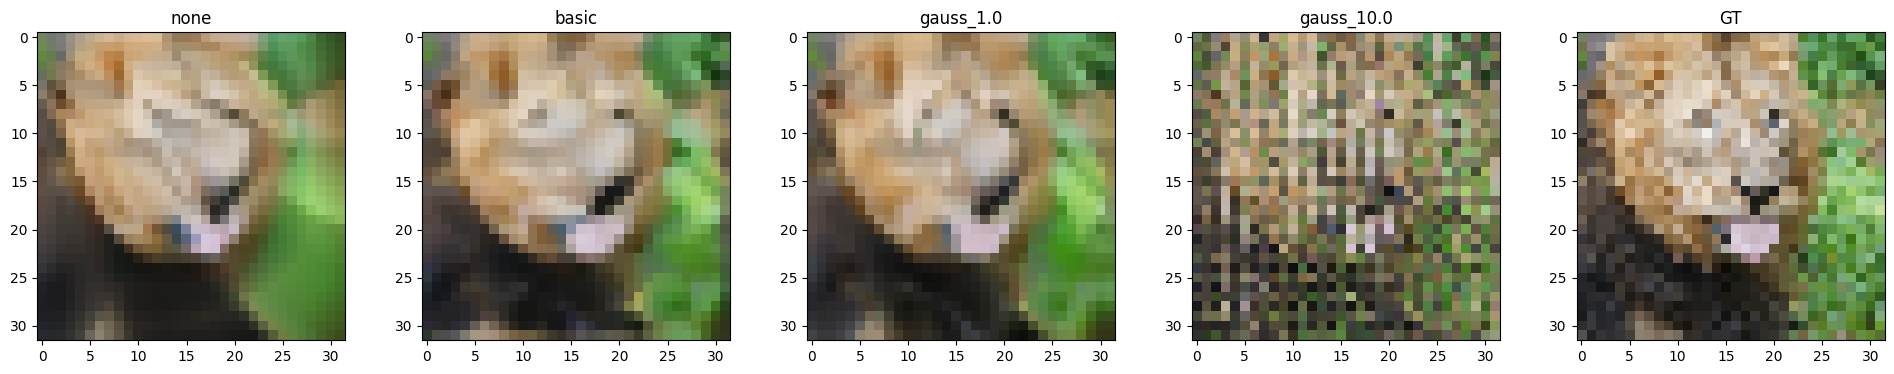

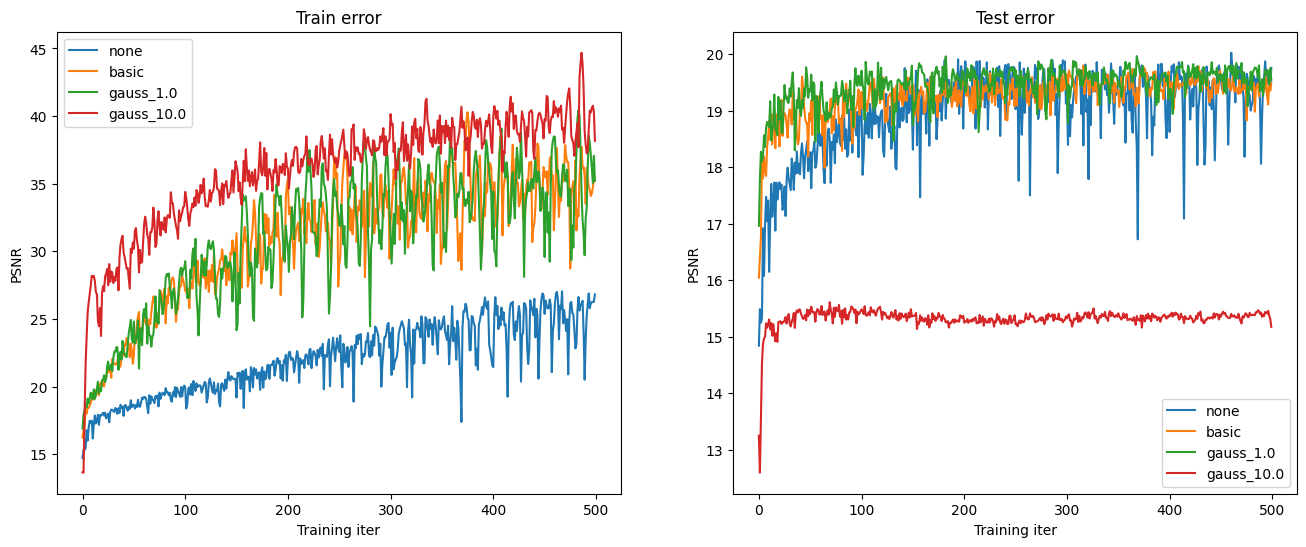

Final Test PSNR for none 19.759281048974625
Final Test PSNR for basic 19.489379917766264
Final Test PSNR for gauss_1.0 19.551021613252615
Final Test PSNR for gauss_10.0 15.175722552828388


In [77]:
# if you did everything correctly so far, this should output a nice figure you can use in your report
plot_feature_mapping_comparison(outputs, y_test.reshape(size,size,3))

#### High Resolution Reconstruction - Adam - Various Input Mapping Strategies

Repeat the previous experiment, but at the higher resolution. We have you first experiment with the lower resolution since it is faster to train and debug. Additionally, you will see how the mapping strategies perform better or worse at the two different input resolutions. 

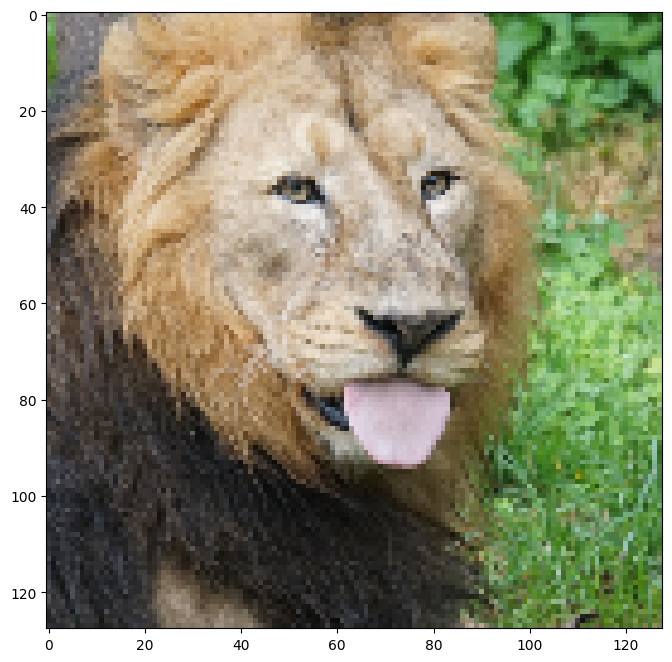

B_dict items:
	 none ()
	 basic (2, 2)
	 gauss_1.0 (64, 2)
	 gauss_10.0 (64, 2)


training none


training basic


training gauss_1.0


training gauss_10.0


In [78]:
# load image
size = 128
train_data, test_data = get_image(size)

B_dict = get_B_dict(size)

print('B_dict items:')
for k,v in B_dict.items():
    print('\t',k,np.array(v).shape)

# start training
outputs = {}
for k in tqdm(B_dict):
  print("training", k)
  outputs[k] = train_wrapper(k, size, num_layers, hidden_size, output_size, epochs, adam_lr, opt='Adam')

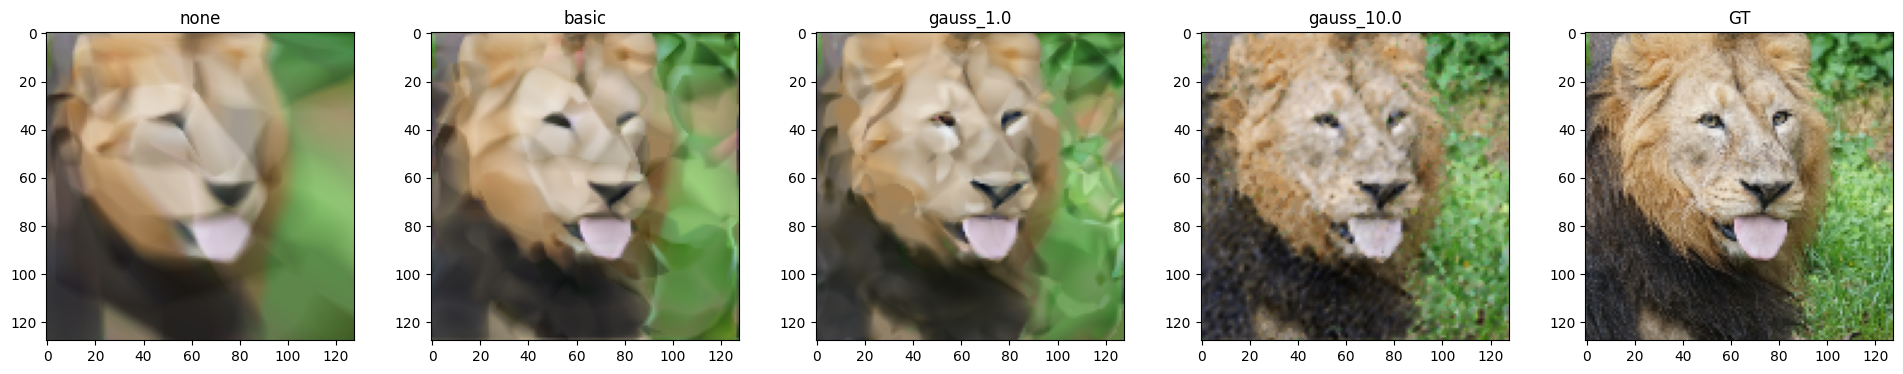

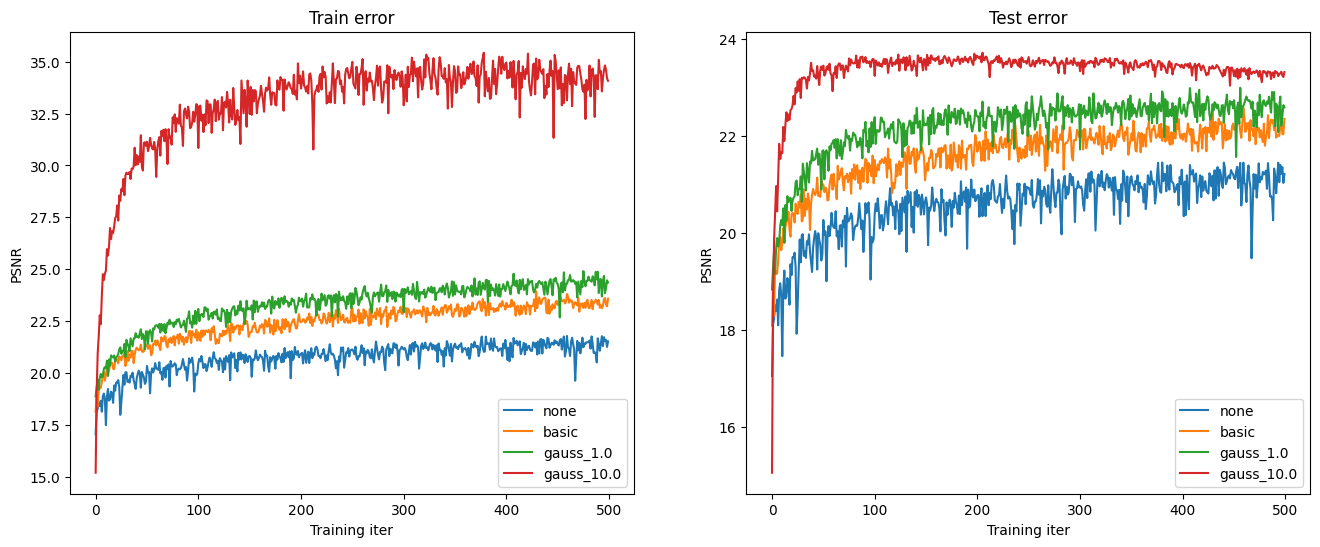

Final Test PSNR for none 21.214766811877737
Final Test PSNR for basic 22.35467885846117
Final Test PSNR for gauss_1.0 22.59293207707494
Final Test PSNR for gauss_10.0 23.320150925944574


In [79]:
_, _, _, y_test = get_input_features(B_dict, "none")  # for getting y_test

# if you did everything correctly so far, this should output a nice figure you can use in your report
plot_feature_mapping_comparison(outputs, y_test.reshape(size,size,3))